# **Import Library**

In [ ]:
!pip install river

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive, files

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

from river import compose
from river import preprocessing
from river import naive_bayes
from river import metrics

from collections import defaultdict

# **Mount Google Drive**

In [ ]:
drive.mount('/content/drive')

base_path = "/content/drive/Shareddrives/PROJECT DATMIN KEL. 11/Coffee Shop Sales.xlsx"

Mounted at /content/drive


# **Load Dataset**

In [ ]:
df = pd.read_excel(base_path, sheet_name="Transactions")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


# **Analisis Data Awal**

## **Understanding Data Stream**

In [ ]:
print("Jumlah baris dan kolom:")
print(df.shape)

print("\nNama Kolom:")
print(df.columns)

print("\nInformasi Dataset:")
print(df.info())

Jumlah baris dan kolom:
(149116, 11)

Nama Kolom:
Index(['transaction_id', 'transaction_date', 'transaction_time',
       'transaction_qty', 'store_id', 'store_location', 'product_id',
       'unit_price', 'product_category', 'product_type', 'product_detail'],
      dtype='object')

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-nu

## **Missing Value dan Duplicate Checking**

In [ ]:
print("Jumlah Missing Value:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Jumlah Missing Value:
transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

Jumlah Data Duplikat:
0


## **Rentang Waktu Transaksi**

In [ ]:
print("Tanggal transaksi paling awal:")
print(df["transaction_date"].min())

print("\nTanggal transaksi paling akhir:")
print(df["transaction_date"].max())

print("\nJumlah hari transaksi:")
print(df["transaction_date"].nunique())

Tanggal transaksi paling awal:
2023-01-01 00:00:00

Tanggal transaksi paling akhir:
2023-06-30 00:00:00

Jumlah hari transaksi:
181


## **Visualisasi Distribusi Product Category**

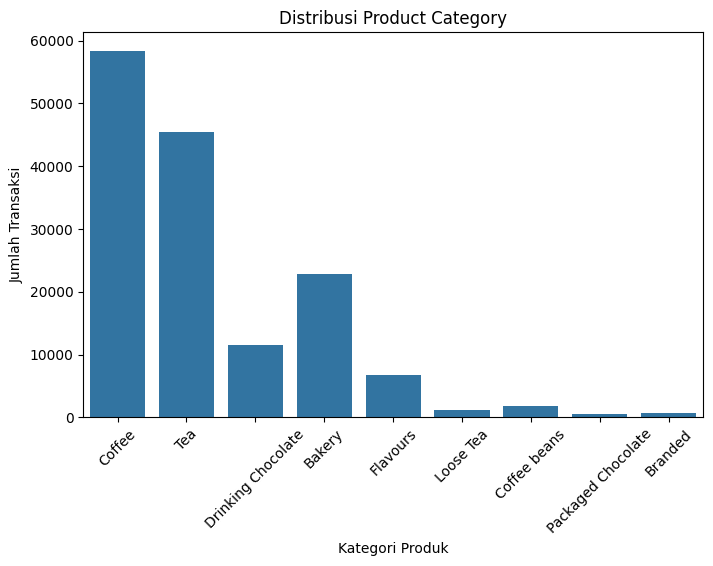

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="product_category"
)

plt.title("Distribusi Product Category")
plt.xlabel("Kategori Produk")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.show()

## **Visualisasi Distribusi Store Location**

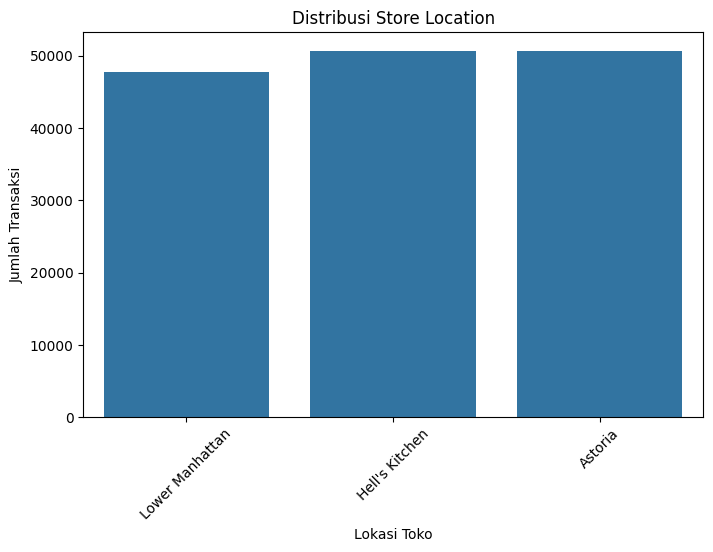

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="store_location"
)

plt.title("Distribusi Store Location")
plt.xlabel("Lokasi Toko")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.show()

# **Pre Processing**

## **Data Cleaning**

In [ ]:
df["datetime"] = pd.to_datetime(
    df["transaction_date"].astype(str) + " " + df["transaction_time"].astype(str),
    errors="coerce"
)

df["transaction_qty"] = pd.to_numeric(df["transaction_qty"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

df = df.dropna(
    subset=[
        "datetime",
        "transaction_qty",
        "unit_price",
        "store_location",
        "product_category",
        "product_type"
    ]
)

df["total_sales"] = df["transaction_qty"] * df["unit_price"]

print("Jumlah data setelah cleaning dasar:")
print(df.shape)

display(df.head())

Jumlah data setelah cleaning dasar:
(149116, 13)


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,datetime,total_sales
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,2023-01-01 07:06:11,6.0
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,2023-01-01 07:08:56,6.2
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,2023-01-01 07:14:04,9.0
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2023-01-01 07:20:24,2.0
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,2023-01-01 07:22:41,6.2


## **Filter Data Kategori Coffee**

In [ ]:
df_coffee = df[df["product_category"] == "Coffee"].copy()

print("Jumlah data kategori Coffee:")
print(df_coffee.shape[0])

print("\nDistribusi target product_type kategori Coffee:")
print(df_coffee["product_type"].value_counts())

Jumlah data kategori Coffee:
58416

Distribusi target product_type kategori Coffee:
product_type
Gourmet brewed coffee    16912
Barista Espresso         16403
Organic brewed coffee     8489
Drip coffee               8477
Premium brewed coffee     8135
Name: count, dtype: int64


## **Outlier Detection**

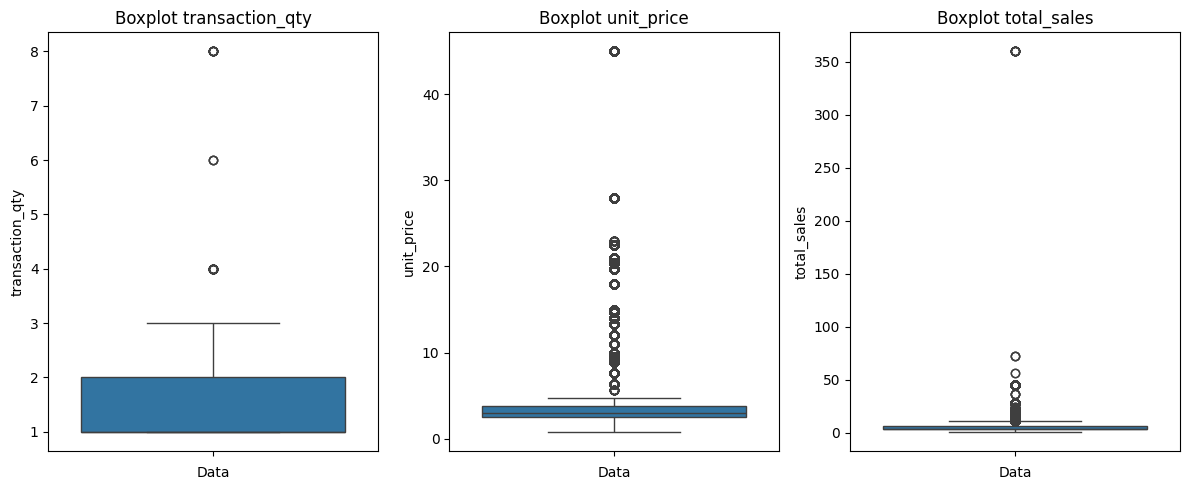

In [ ]:
numerical_cols = [
    "transaction_qty",
    "unit_price",
    "total_sales"
]

plt.figure(figsize=(12,5))

for i, col in enumerate(numerical_cols):

    plt.subplot(1,3,i+1)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot {col}")
    plt.xlabel("Data")
    plt.ylabel(col)
plt.tight_layout()
plt.show()

## **Mengecek Outlier dengan IQR**

In [ ]:
outlier_summary = []

for col in numerical_cols:
    Q1 = df_coffee[col].quantile(0.25)
    Q3 = df_coffee[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outlier = df_coffee[
        (df_coffee[col] < lower_bound) |
        (df_coffee[col] > upper_bound)
    ]

    outlier_summary.append({
        "kolom": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "jumlah_outlier": len(outlier),
        "persentase_outlier": (len(outlier) / len(df_coffee)) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

print("Ringkasan Outlier:")
display(outlier_df)

Ringkasan Outlier:


,kolom,Q1,Q3,IQR,lower_bound,upper_bound,jumlah_outlier,persentase_outlier
0,transaction_qty,1.00,2.0,1.00,-0.500,3.500,2,0.003424
1,unit_price,2.45,3.5,1.05,0.875,5.075,0,0.000000
2,total_sales,3.00,6.0,3.00,-1.500,10.500,378,0.647083


## **Handling Outlier dengan Capping IQR**

In [ ]:
df_coffee_before_outlier = df_coffee.copy()

for col in numerical_cols:
    Q1 = df_coffee[col].quantile(0.25)
    Q3 = df_coffee[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df_coffee[col] = np.where(
        df_coffee[col] < lower_bound,
        lower_bound,
        df_coffee[col]
    )

    df_coffee[col] = np.where(
        df_coffee[col] > upper_bound,
        upper_bound,
        df_coffee[col]
    )

print("Handling outlier selesai menggunakan metode capping IQR.")

Handling outlier selesai menggunakan metode capping IQR.


## **Boxplot Setelah Handling Outlier**

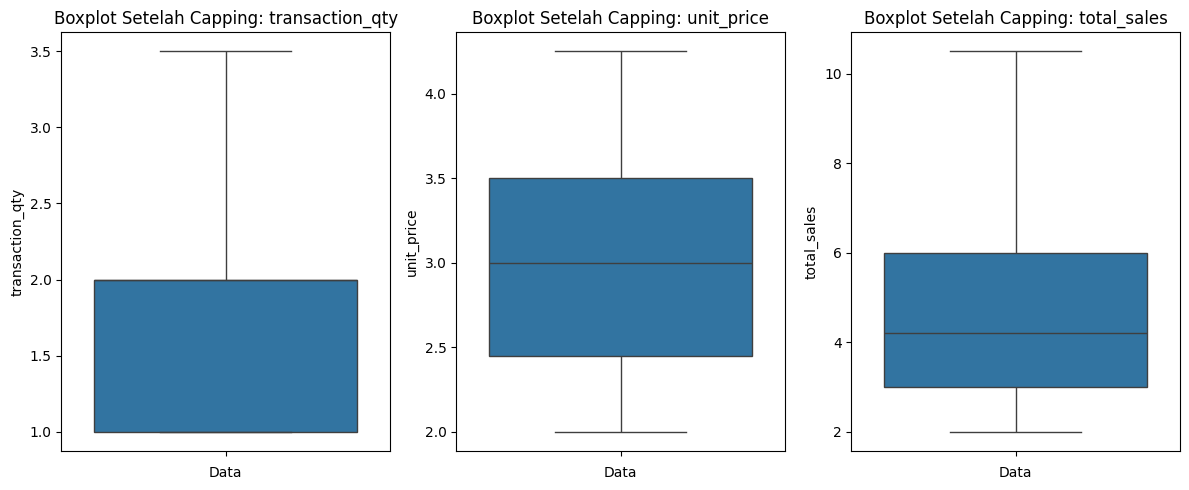

In [ ]:
plt.figure(figsize=(12, 5))

for i, col in enumerate(numerical_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df_coffee[col])
    plt.title(f"Boxplot Setelah Capping: {col}")
    plt.xlabel("Data")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

## **Feature Engineering Berbasis Waktu**

In [ ]:
df_coffee = df_coffee.sort_values(by="datetime").reset_index(drop=True)

df_coffee["hour"] = df_coffee["datetime"].dt.hour
df_coffee["day"] = df_coffee["datetime"].dt.day
df_coffee["month"] = df_coffee["datetime"].dt.month
df_coffee["day_of_week"] = df_coffee["datetime"].dt.dayofweek
df_coffee["is_weekend"] = (df_coffee["day_of_week"] >= 5).astype(int)

def kategori_waktu(hour):
    if hour < 12:
        return "Pagi"
    elif hour < 18:
        return "Siang"
    else:
        return "Malam"

df_coffee["time_category"] = df_coffee["hour"].apply(kategori_waktu)

df_coffee["is_morning"] = (df_coffee["hour"] < 12).astype(int)
df_coffee["is_peak_hour"] = df_coffee["hour"].isin([8, 9, 10]).astype(int)

df_coffee["sales_category"] = pd.cut(
    df_coffee["total_sales"],
    bins=[-np.inf, 5, 10, 20, np.inf],
    labels=["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
)

df_coffee["sales_category"] = df_coffee["sales_category"].astype(str)

print("Data sudah diurutkan berdasarkan waktu transaksi.")
print("\nWaktu transaksi paling awal:")
print(df_coffee["datetime"].min())

print("\nWaktu transaksi paling akhir:")
print(df_coffee["datetime"].max())

print("\nJumlah data stream:")
print(len(df_coffee))

display(df_coffee.head())

Data sudah diurutkan berdasarkan waktu transaksi.

Waktu transaksi paling awal:
2023-01-01 07:06:11

Waktu transaksi paling akhir:
2023-06-30 20:57:19

Jumlah data stream:
58416


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,...,total_sales,hour,day,month,day_of_week,is_weekend,time_category,is_morning,is_peak_hour,sales_category
0,1,2023-01-01,07:06:11,2.0,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,...,6.00,7,1,1,6,1,Pagi,1,0,Sedang
1,4,2023-01-01,07:20:24,1.0,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,...,2.00,7,1,1,6,1,Pagi,1,0,Rendah
2,7,2023-01-01,07:25:49,1.0,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,...,2.00,7,1,1,6,1,Pagi,1,0,Rendah
3,8,2023-01-01,07:33:34,2.0,5,Lower Manhattan,28,2.00,Coffee,Gourmet brewed coffee,...,4.00,7,1,1,6,1,Pagi,1,0,Rendah
4,9,2023-01-01,07:39:13,1.0,5,Lower Manhattan,39,4.25,Coffee,Barista Espresso,...,4.25,7,1,1,6,1,Pagi,1,0,Rendah


# **Analisis Pola Pembelian Kopi**

## **Distribusi Target Product Type**

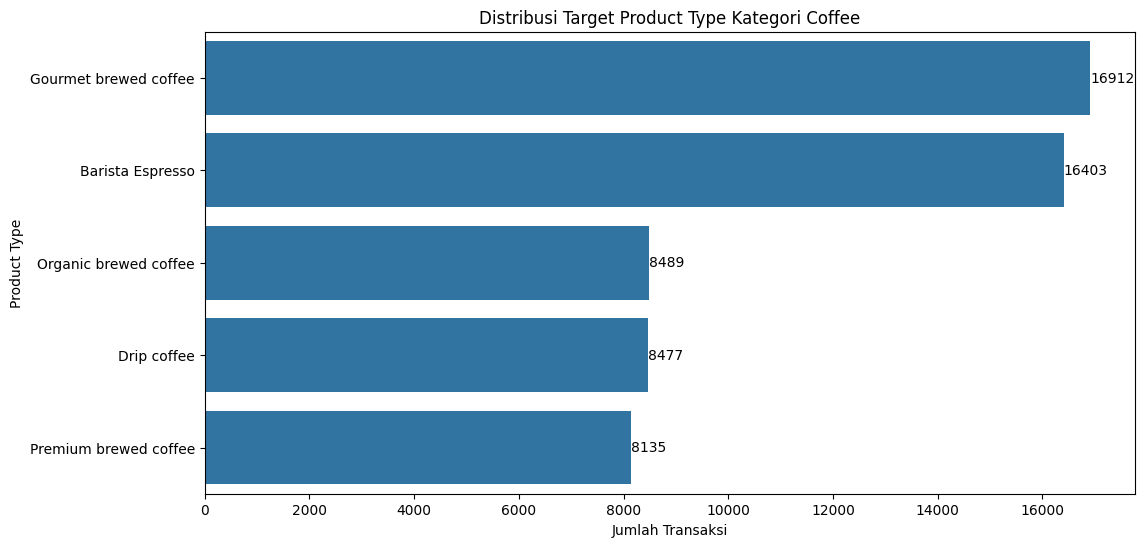

Jenis kopi yang paling sering dibeli adalah: Gourmet brewed coffee


In [ ]:
plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=df_coffee,
    y="product_type",
    order=df_coffee["product_type"].value_counts().index
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribusi Target Product Type Kategori Coffee")
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Product Type")
plt.show()

kopi_terlaris = df_coffee["product_type"].value_counts().idxmax()
print(f"Jenis kopi yang paling sering dibeli adalah: {kopi_terlaris}")

## **Analisis Pola Pembelian Berdasarkan Jam**

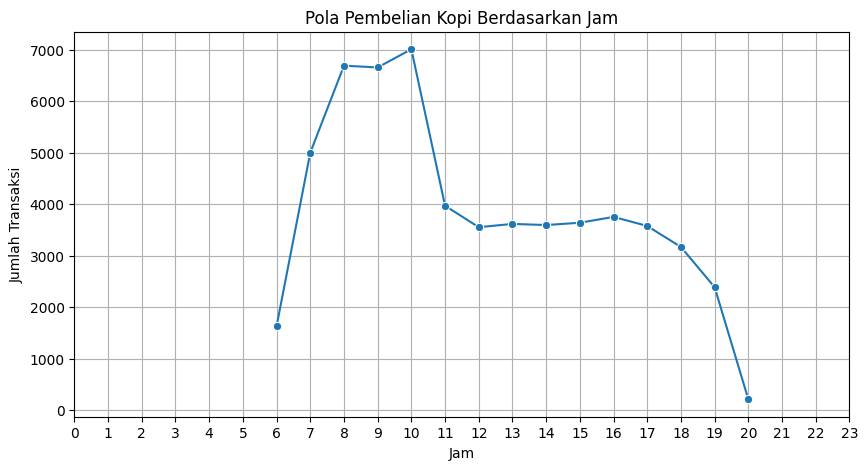

,hour,jumlah_transaksi
0,6,1629
1,7,4997
2,8,6687
3,9,6652
4,10,7006
5,11,3967
6,12,3550
7,13,3614
8,14,3592
9,15,3637


In [ ]:
hourly_sales = (
    df_coffee.groupby("hour")
    .size()
    .reset_index(name="jumlah_transaksi")
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly_sales,
    x="hour",
    y="jumlah_transaksi",
    marker="o"
)

plt.title("Pola Pembelian Kopi Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Jumlah Transaksi")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

display(hourly_sales)

## **Analisis Pola Pembelian Berdasarkan Hari**

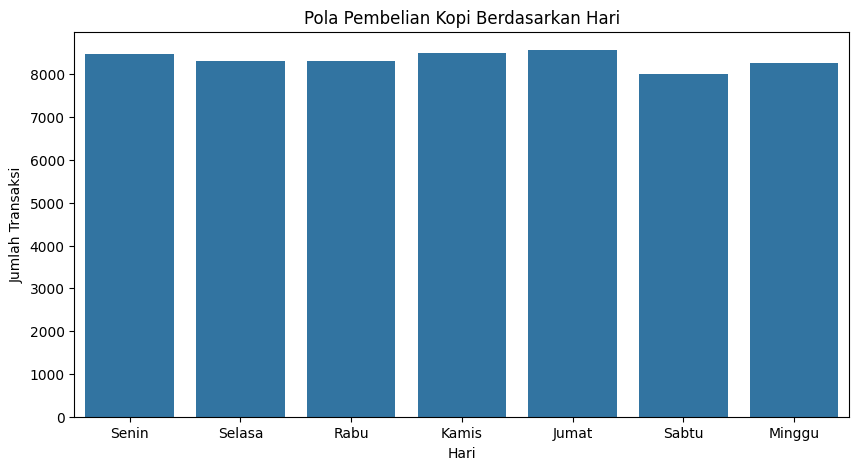

,nama_hari,jumlah_transaksi
0,Senin,8468
1,Selasa,8304
2,Rabu,8315
3,Kamis,8488
4,Jumat,8567
5,Sabtu,8013
6,Minggu,8261


In [ ]:
hari_map = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

df_coffee["nama_hari"] = df_coffee["day_of_week"].map(hari_map)

daily_sales = (
    df_coffee.groupby("nama_hari")
    .size()
    .reindex(["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"])
    .reset_index(name="jumlah_transaksi")
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=daily_sales,
    x="nama_hari",
    y="jumlah_transaksi"
)

plt.title("Pola Pembelian Kopi Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Jumlah Transaksi")
plt.show()

display(daily_sales)

## **Analisis Penjualan Berdasarkan Lokasi**

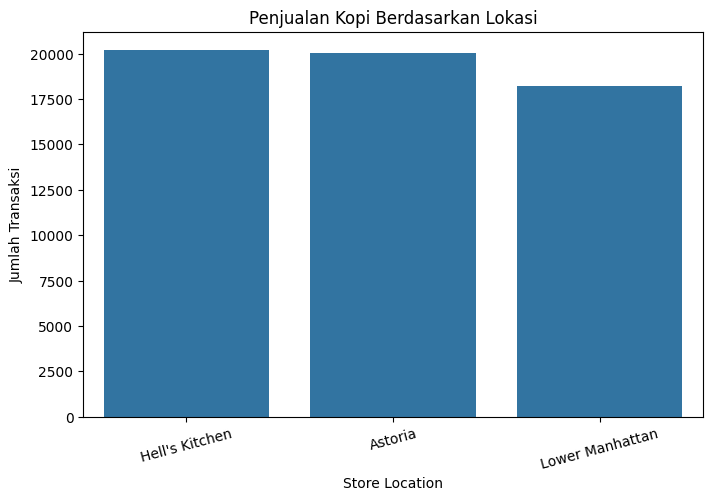

,store_location,jumlah_transaksi
1,Hell's Kitchen,20187
0,Astoria,20025
2,Lower Manhattan,18204


In [ ]:
location_sales = (
    df_coffee.groupby("store_location")
    .size()
    .reset_index(name="jumlah_transaksi")
    .sort_values(by="jumlah_transaksi", ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=location_sales,
    x="store_location",
    y="jumlah_transaksi"
)

plt.title("Penjualan Kopi Berdasarkan Lokasi")
plt.xlabel("Store Location")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=15)
plt.show()

display(location_sales)

## **Windowing Process**

In [ ]:
window_size = 1000
jumlah_window = int(np.ceil(len(df_coffee) / window_size))

print("Ukuran window:", window_size)
print("Jumlah data stream:", len(df_coffee))
print("Jumlah window:", jumlah_window)

print("\nKeterangan:")
print("Window digunakan untuk mengevaluasi performa model setiap 1000 data transaksi.")

Ukuran window: 1000
Jumlah data stream: 58416
Jumlah window: 59

Keterangan:
Window digunakan untuk mengevaluasi performa model setiap 1000 data transaksi.


## **Menentukan Feature dan Target**

In [ ]:
target = 'product_type'
categorical_features = ['store_location', 'time_category', 'product_detail']
numerical_features = ['transaction_qty', 'unit_price', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'is_morning', 'is_peak_hour']
feature_cols = categorical_features + numerical_features

X = df_coffee[feature_cols]
y = df_coffee[target]
print("Fitur kategorikal:")
print(categorical_features)

print("\nFitur numerik:")
print(numerical_features)

print("\nTarget:")
print(target)

print("\nJumlah fitur:")
print(len(feature_cols))

print("\nJumlah kelas target:")
print(df_coffee[target].nunique())

print("\nDaftar kelas target:")
print(df_coffee[target].unique())

Fitur kategorikal:
['store_location', 'time_category', 'product_detail']

Fitur numerik:
['transaction_qty', 'unit_price', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'is_morning', 'is_peak_hour']

Target:
product_type

Jumlah fitur:
12

Jumlah kelas target:
5

Daftar kelas target:
['Gourmet brewed coffee' 'Drip coffee' 'Barista Espresso'
 'Organic brewed coffee' 'Premium brewed coffee']


## **Membuat Model Gaussian Naive Bayes Incremental**

In [ ]:
model_pipeline = compose.Pipeline(
    preprocessing.OneHotEncoder(),
    preprocessing.StandardScaler(),
    naive_bayes.GaussianNB()
)

## **Warm-Up Model**

In [ ]:
warmup_size = 1000
X_warmup = X.iloc[:warmup_size]
y_warmup = y.iloc[:warmup_size]

for i in range(warmup_size):
    model_pipeline.learn_one(X_warmup.iloc[i].to_dict(), y_warmup.iloc[i])

print("Warm-up model selesai")

Warm-up model selesai


## **Inisialisasi Variabel Evaluasi Stream**

In [ ]:
y_true = []
y_pred = []
evaluated_records = []

running_accuracy = []
metric_acc = metrics.Accuracy()
stream_index = []

evaluated_count = 0

print("Variabel evaluasi berhasil.")

Variabel evaluasi berhasil.


# **Proses Data Stream: Predict-Then-Learn**

In [ ]:
window = 1000
evaluated_count = 0
y_true = []
y_pred = []
running_accuracy = []

metric_acc = metrics.Accuracy()
drift_threshold = 0.1

for i in range(warmup_size, len(df_coffee)):

    x_instance = df_coffee[feature_cols].iloc[i].to_dict()
    y_instance = df_coffee[target].iloc[i]

    y_hat = model_pipeline.predict_one(x_instance)
    y_pred.append(y_hat)
    y_true.append(y_instance)

    model_pipeline.learn_one(x_instance, y_instance)

    metric_acc.update(y_instance, y_hat)
    evaluated_count += 1

    if evaluated_count % window == 0:
        current_acc = metric_acc.get()
        running_accuracy.append((evaluated_count, current_acc))
        print(f"Data stream ke-{evaluated_count}")
        print(f"Running Accuracy GaussianNB : {current_acc:.4f}")
        print("-" * 50)

        if len(running_accuracy) > 1:
            prev_acc = running_accuracy[-2][1]
            if prev_acc - current_acc > drift_threshold:
                print(f"[WARNING] Concept drift terdeteksi! Akurasi turun {prev_acc - current_acc:.4f}")

print("Proses data stream selesai.")

Data stream ke-1000
Running Accuracy GaussianNB : 0.7830
--------------------------------------------------
Data stream ke-2000
Running Accuracy GaussianNB : 0.7625
--------------------------------------------------
Data stream ke-3000
Running Accuracy GaussianNB : 0.7630
--------------------------------------------------
Data stream ke-4000
Running Accuracy GaussianNB : 0.7528
--------------------------------------------------
Data stream ke-5000
Running Accuracy GaussianNB : 0.7574
--------------------------------------------------
Data stream ke-6000
Running Accuracy GaussianNB : 0.7602
--------------------------------------------------
Data stream ke-7000
Running Accuracy GaussianNB : 0.7530
--------------------------------------------------
Data stream ke-8000
Running Accuracy GaussianNB : 0.7628
--------------------------------------------------
Data stream ke-9000
Running Accuracy GaussianNB : 0.7670
--------------------------------------------------
Data stream ke-10000
Running

# **Evaluasi**


## **Hasil Evaluasi Akhir Model**

In [ ]:
final_accuracy = accuracy_score(y_true, y_pred)

final_weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("HASIL EVALUASI AKHIR")
print(f"Akurasi Gaussian Naive Bayes : {final_accuracy * 100:.2f}%")
print(f"Weighted F1-Score           : {final_weighted_f1:.4f}")
print(f"Macro F1-Score              : {final_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        zero_division=0,
        digits=3
    )
)

HASIL EVALUASI AKHIR
Akurasi Gaussian Naive Bayes : 69.05%
Weighted F1-Score           : 0.6680
Macro F1-Score              : 0.6905

Classification Report:
                       precision    recall  f1-score   support

     Barista Espresso      1.000     0.608     0.756     16139
          Drip coffee      0.638     0.999     0.779      8316
Gourmet brewed coffee      0.999     0.314     0.478     16652
Organic brewed coffee      0.494     1.000     0.661      8322
Premium brewed coffee      0.638     1.000     0.779      7987

             accuracy                          0.691     57416
            macro avg      0.754     0.784     0.691     57416
         weighted avg      0.824     0.691     0.668     57416



## **Confusion Matrix Gaussian Naive Bayes**

<Figure size 1000x800 with 0 Axes>

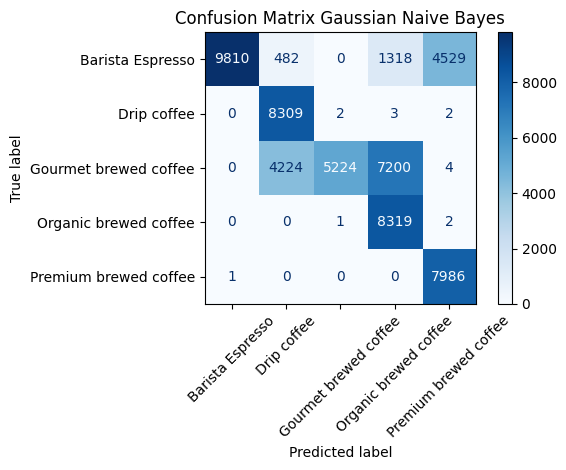

In [ ]:
classes = sorted(df_coffee[target].unique())

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Confusion Matrix Gaussian Naive Bayes")
plt.tight_layout()
plt.show()

## **Visualisasi Running Accuracy**

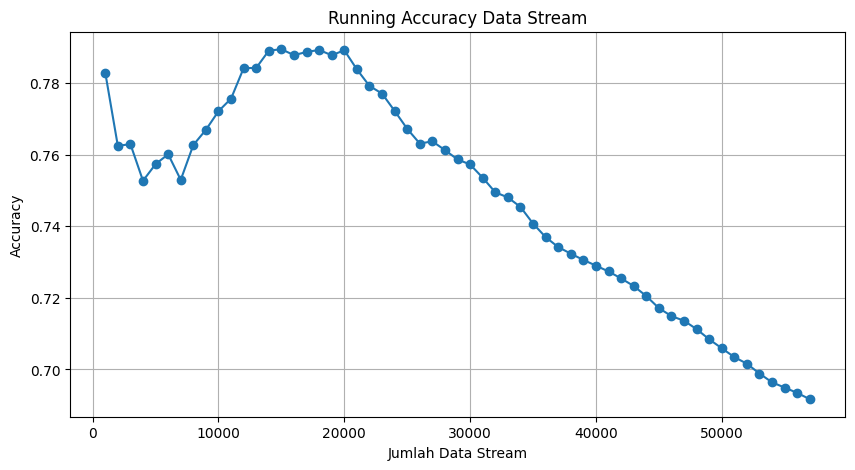

In [ ]:
stream_index, stream_acc = zip(*running_accuracy)  # unzip tuple menjadi dua list

plt.figure(figsize=(10, 5))
plt.plot(
    stream_index,
    stream_acc,
    marker="o"
)
plt.title("Running Accuracy Data Stream")
plt.xlabel("Jumlah Data Stream")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

## **Ringkasan Hasil Prediksi**

In [ ]:
result_df = pd.DataFrame({'actual_product_type': y_true, 'predicted_product_type': y_pred})

result_df["status"] = np.where(
    result_df["actual_product_type"] == result_df["predicted_product_type"],
    "Benar",
    "Salah"
)

print("Jumlah hasil prediksi:")
print(result_df.shape)

print("\nRingkasan hasil prediksi:")
print(result_df["status"].value_counts())

print("\nPersentase hasil prediksi:")
print(result_df["status"].value_counts(normalize=True) * 100)

display(result_df.sample(20, random_state=5))

Jumlah hasil prediksi:
(57416, 3)

Ringkasan hasil prediksi:
status
Benar    39648
Salah    17768
Name: count, dtype: int64

Persentase hasil prediksi:
status
Benar    69.053922
Salah    30.946078
Name: proportion, dtype: float64


,actual_product_type,predicted_product_type,status
42474,Barista Espresso,Barista Espresso,Benar
51970,Premium brewed coffee,Premium brewed coffee,Benar
48486,Barista Espresso,Premium brewed coffee,Salah
6909,Gourmet brewed coffee,Organic brewed coffee,Salah
56417,Barista Espresso,Premium brewed coffee,Salah
17915,Gourmet brewed coffee,Gourmet brewed coffee,Benar
40197,Gourmet brewed coffee,Gourmet brewed coffee,Benar
9595,Gourmet brewed coffee,Gourmet brewed coffee,Benar
40940,Premium brewed coffee,Premium brewed coffee,Benar
43892,Organic brewed coffee,Organic brewed coffee,Benar


## **Analisis Kesalahan Prediksi Per Kelas**

In [ ]:
error_by_class = (
    result_df[result_df["status"] == "Salah"]
    .groupby("actual_product_type")
    .size()
    .reset_index(name="jumlah_salah")
    .sort_values(by="jumlah_salah", ascending=False)
)

print("Jumlah kesalahan prediksi berdasarkan kelas asli:")
display(error_by_class)

Jumlah kesalahan prediksi berdasarkan kelas asli:


,actual_product_type,jumlah_salah
2,Gourmet brewed coffee,11428
0,Barista Espresso,6329
1,Drip coffee,7
3,Organic brewed coffee,3
4,Premium brewed coffee,1


## **Analisis Bisnis Sederhana**

In [ ]:
kopi_terlaris = df_coffee["product_type"].value_counts().head(5)
jam_ramai = df_coffee["hour"].value_counts().sort_values(ascending=False).head(5)
lokasi_teramai = df_coffee["store_location"].value_counts().head(5)

print("Kopi paling banyak dibeli:")
print(kopi_terlaris)

print("\nJam transaksi kopi paling ramai:")
print(jam_ramai)

print("\nLokasi toko dengan transaksi kopi terbanyak:")
print(lokasi_teramai)

Kopi paling banyak dibeli:
product_type
Gourmet brewed coffee    16912
Barista Espresso         16403
Organic brewed coffee     8489
Drip coffee               8477
Premium brewed coffee     8135
Name: count, dtype: int64

Jam transaksi kopi paling ramai:
hour
10    7006
8     6687
9     6652
7     4997
11    3967
Name: count, dtype: int64

Lokasi toko dengan transaksi kopi terbanyak:
store_location
Hell's Kitchen     20187
Astoria            20025
Lower Manhattan    18204
Name: count, dtype: int64


In [ ]:
result_df.to_csv("hasil_prediksi_stream_gnb.csv", index=False)

print("File hasil berhasil disimpan:")
print("hasil_prediksi_stream_gnb.csv")

File hasil berhasil disimpan:
hasil_prediksi_stream_gnb.csv


In [ ]:
files.download('hasil_prediksi_stream_gnb.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df=pd.read_excel('Coffee Shop Sales.xlsx')

In [ ]:
display(df)

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
...,...,...,...,...,...,...,...,...,...,...,...
149111,149452,2023-06-30,20:18:41,2,8,Hell's Kitchen,44,2.50,Tea,Brewed herbal tea,Peppermint Rg
149112,149453,2023-06-30,20:25:10,2,8,Hell's Kitchen,49,3.00,Tea,Brewed Black tea,English Breakfast Lg
149113,149454,2023-06-30,20:31:34,1,8,Hell's Kitchen,45,3.00,Tea,Brewed herbal tea,Peppermint Lg
149114,149455,2023-06-30,20:57:19,1,8,Hell's Kitchen,40,3.75,Coffee,Barista Espresso,Cappuccino


In [ ]:
df[['transaction_time']]

,transaction_time
0,07:06:11
1,07:08:56
2,07:14:04
3,07:20:24
4,07:22:41
...,...
149111,20:18:41
149112,20:25:10
149113,20:31:34
149114,20:57:19
